# EchoChain: Circular Economy & Secondary Market Lifecycle Analytics

Manufacturers track products rigorously until the point of sale. After that, the
lifecycle is a data blind spot, which makes it hard to measure environmental impact,
landfill diversion, or the potential for profitable refurbishment.

This notebook joins **internal BOM and warranty data** with **secondary-market
listings** to answer one question per product model: *is it worth running a buy-back
and refurbishment program?*

**Pipeline:** generate data → clean and fuzzy-match listings to SKUs → aggregate
resale value → compute a Circularity Score → visualise → export.

> **Note on data:** live marketplace scraping is restricted by site terms of service,
> so the listings here are simulated with the same shape and messiness a real scrape
> would have. The scores demonstrate the method, not real findings about these laptops.

## 1. Setup

In [1]:
import os
import re
import random
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from faker import Faker
from rapidfuzz import fuzz, process, utils

random.seed(42)
Faker.seed(42)
fake = Faker()

OUTPUT_DIR = "outputs"
DB_PATH = "echochain.db"
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 2. Internal data: the Bill of Materials (BOM)

Each laptop model has five components. Every component has a unit cost, a warranty
failure rate, and a flag for whether it is **critical**. A critical component is one
whose failure usually means the whole device is scrapped (the motherboard) rather
than repaired. Some models are deliberately made less reliable so the data has
something to find.

In [2]:
MODELS = ["Dell XPS 15", "HP Pavilion 14", "Lenovo ThinkPad T14",
          "Asus VivoBook 15", "Acer Aspire 5"]

# component: (unit_cost_usd, is_critical)
COMPONENTS = {
    "Motherboard":   (180, True),
    "Display Panel": (90,  False),
    "Battery":       (35,  False),
    "RAM Module":    (25,  False),
    "SSD Storage":   (45,  False),
}

# multiplier on base failure rates: >1 = less reliable, <1 = more reliable
MODEL_RELIABILITY = {"Dell XPS 15": 1.4, "HP Pavilion 14": 0.8,
                     "Lenovo ThinkPad T14": 0.6, "Asus VivoBook 15": 1.1,
                     "Acer Aspire 5": 1.0}

BASE_FAILURE_RATE = {"Motherboard": 9.0, "Display Panel": 4.0, "Battery": 11.0,
                     "RAM Module": 1.5, "SSD Storage": 2.5}

def generate_bom():
    rows, sku = [], 1000
    for model in MODELS:
        for component, (cost, critical) in COMPONENTS.items():
            sku += 1
            rate = BASE_FAILURE_RATE[component] * MODEL_RELIABILITY[model] * random.uniform(0.85, 1.15)
            rows.append({"sku": f"SKU-{sku}", "model": model, "component": component,
                         "unit_cost_usd": cost, "critical_component": critical,
                         "warranty_failure_rate_pct": round(rate, 2)})
    return pd.DataFrame(rows)

bom = generate_bom()
bom.head(10)

,sku,model,component,unit_cost_usd,critical_component,warranty_failure_rate_pct
0,SKU-1001,Dell XPS 15,Motherboard,180,True,13.13
1,SKU-1002,Dell XPS 15,Display Panel,90,False,4.80
2,SKU-1003,Dell XPS 15,Battery,35,False,14.36
3,SKU-1004,Dell XPS 15,RAM Module,25,False,1.93
4,SKU-1005,Dell XPS 15,SSD Storage,45,False,3.75
5,SKU-1006,HP Pavilion 14,Motherboard,180,True,7.58
6,SKU-1007,HP Pavilion 14,Display Panel,90,False,3.58
7,SKU-1008,HP Pavilion 14,Battery,35,False,7.71
8,SKU-1009,HP Pavilion 14,RAM Module,25,False,1.17
9,SKU-1010,HP Pavilion 14,SSD Storage,45,False,1.72


## 3. Simulated secondary-market listings

Real scraped data is messy: brand names are misspelled, spacing is inconsistent, and
most listings are for parts rather than whole devices. The generator reproduces that,
and keeps the true model and component in hidden `_true_*` columns **only so we can
measure how accurate the matcher is later**. A real scrape would not have them.

In [3]:
CONDITIONS = ["New", "Open Box", "Used - Like New", "Used - Good",
              "Used - Fair", "For Parts/Repair"]

MODEL_ALIASES = {
    "Dell XPS 15": ["Dell XPS 15 9530", "DELL XPS15", "Dell Xps 15 laptop", "XPS 15 9520"],
    "HP Pavilion 14": ["HP Pavilion 14", "HP Pavillion 14 dv", "Hewlett Packard Pavilion 14"],
    "Lenovo ThinkPad T14": ["Lenovo ThinkPad T14", "ThinkPad T14 Gen 2", "Lenovo Think Pad T 14"],
    "Asus VivoBook 15": ["ASUS Vivobook 15", "Asus Vivo Book 15", "Asus VivoBook15 X1500"],
    "Acer Aspire 5": ["Acer Aspire 5", "ACER ASPIRE5", "Acer Aspire-5 A515"],
}

COMPONENT_PHRASES = {
    "Display Panel": ["LCD screen assembly", "display panel replacement", "screen (genuine OEM)", "LED display"],
    "Battery": ["replacement battery", "OEM battery pack", "battery (used, tested)"],
    "Motherboard": ["motherboard (untested)", "logic board for parts", "motherboard - boots fine"],
    "RAM Module": ["RAM stick", "memory module"],
    "SSD Storage": ["SSD drive", "NVMe storage"],
}

PLATFORMS = ["eBay", "OLX", "Cashify", "Quikr"]
CONDITION_MULT = {"New": 1.1, "Open Box": 0.9, "Used - Like New": 0.75,
                  "Used - Good": 0.55, "Used - Fair": 0.35, "For Parts/Repair": 0.2}

def generate_listings(bom_df, n=600):
    rows = []
    for _ in range(n):
        row = bom_df.sample(1).iloc[0]
        model, component = row["model"], row["component"]
        is_part = random.random() < 0.55
        condition = random.choice(CONDITIONS)

        if is_part:
            title = f"{random.choice(MODEL_ALIASES[model])} {random.choice(COMPONENT_PHRASES[component])} {condition}"
            base = row["unit_cost_usd"]
        else:
            title = f"{random.choice(MODEL_ALIASES[model])} laptop {condition}"
            base = row["unit_cost_usd"] * random.uniform(5.5, 7.5)

        if random.random() < 0.15:           # scrape noise: stray space inside a word
            title = title.replace("a", "a ", 1)

        rows.append({
            "listing_id": fake.uuid4()[:8],
            "raw_title": title.strip(),
            "platform": random.choice(PLATFORMS),
            "price_usd": round(base * CONDITION_MULT[condition] * random.uniform(0.85, 1.15), 2),
            "condition": condition,
            "is_part_listing": is_part,
            "_true_model": model,
            "_true_component": component if is_part else "Whole Device",
        })
    return pd.DataFrame(rows)

listings = generate_listings(bom)
listings[["raw_title", "platform", "price_usd", "condition"]].head(10)

,raw_title,platform,price_usd,condition
0,XPS 15 9520 LCD screen assembly New,Cashify,102.08,New
1,HP Pavillion 14 dv laptop For Parts/Repair,Quikr,40.19,For Parts/Repair
2,Dell Xps 15 laptop RAM stick For Parts/Repair,eBay,5.24,For Parts/Repair
3,HP Pavilion 14 laptop New,Quikr,1490.42,New
4,HP Pavillion 14 dv SSD drive Used - Like New,eBay,34.85,Used - Like New
5,Lenovo ThinkPad T14 RAM stick For Parts/Repair,Cashify,5.73,For Parts/Repair
6,Acer Aspire 5 laptop Used - Fair,eBay,77.31,Used - Fair
7,ACER ASPIRE5 logic boa rd for parts Used - Lik...,Cashify,123.36,Used - Like New
8,XPS 15 9520 replacement battery For Parts/Repair,OLX,7.51,For Parts/Repair
9,Lenovo Think Pad T 14 memory module For Parts/...,Quikr,4.79,For Parts/Repair


## 4. Clean and fuzzy-match listings to models and components

Two steps:
1. **Clean** each title: lowercase, strip punctuation, collapse whitespace.
2. **Match** it to the closest model name with `rapidfuzz` (`partial_ratio`), and
   detect the component from keywords. Matches below a confidence cutoff are dropped,
   the way a production job would send them to a review queue.

A note on a bug worth knowing about: `process.extractOne` does **not** lowercase the
choices by default, so comparing a lowercased title to mixed-case model names silently
tanks the score. Passing `processor=utils.default_process` fixes it.

In [4]:
def clean_title(title):
    title = title.lower()
    title = re.sub(r"[^a-z0-9\s]", " ", title)
    return re.sub(r"\s+", " ", title).strip()

COMPONENT_KEYWORDS = {
    "Display Panel": ["screen", "display", "lcd", "led panel", "panel"],
    "Battery": ["battery"],
    "Motherboard": ["motherboard", "logic board"],
    "RAM Module": ["ram", "memory module", "memory stick"],
    "SSD Storage": ["ssd", "nvme", "storage drive"],
}

def match_component(text):
    for component, keywords in COMPONENT_KEYWORDS.items():
        if any(k in text for k in keywords):
            return component
    return "Whole Device"

def match_listings(listings, bom, score_cutoff=70):
    models = bom["model"].unique().tolist()
    out = listings.copy()
    out["clean_title"] = out["raw_title"].apply(clean_title)

    matched, scores = [], []
    for text in out["clean_title"]:
        best = process.extractOne(text, models, scorer=fuzz.partial_ratio,
                                  processor=utils.default_process)
        ok = best is not None and best[1] >= score_cutoff
        matched.append(best[0] if ok else None)
        scores.append(best[1] if best else 0)

    out["matched_model"] = matched
    out["match_score"] = scores
    out["matched_component"] = out["clean_title"].apply(match_component)
    return out[out["matched_model"].notna()].reset_index(drop=True)

matched = match_listings(listings, bom)

model_acc = (matched["matched_model"] == matched["_true_model"]).mean() * 100
comp_acc = (matched["matched_component"] == matched["_true_component"]).mean() * 100
print(f"Matched {len(matched)} of {len(listings)} listings")
print(f"Model-match accuracy:     {model_acc:.1f}%")
print(f"Component-match accuracy: {comp_acc:.1f}%")

matched[["raw_title", "matched_model", "matched_component", "match_score"]].head(10)

Matched 600 of 600 listings
Model-match accuracy:     100.0%
Component-match accuracy: 98.5%


,raw_title,matched_model,matched_component,match_score
0,XPS 15 9520 LCD screen assembly New,Dell XPS 15,Display Panel,70.588235
1,HP Pavillion 14 dv laptop For Parts/Repair,HP Pavilion 14,Whole Device,92.857143
2,Dell Xps 15 laptop RAM stick For Parts/Repair,Dell XPS 15,RAM Module,100.000000
3,HP Pavilion 14 laptop New,HP Pavilion 14,Whole Device,100.000000
4,HP Pavillion 14 dv SSD drive Used - Like New,HP Pavilion 14,SSD Storage,92.857143
5,Lenovo ThinkPad T14 RAM stick For Parts/Repair,Lenovo ThinkPad T14,RAM Module,100.000000
6,Acer Aspire 5 laptop Used - Fair,Acer Aspire 5,Whole Device,100.000000
7,ACER ASPIRE5 logic boa rd for parts Used - Lik...,Acer Aspire 5,Whole Device,96.000000
8,XPS 15 9520 replacement battery For Parts/Repair,Dell XPS 15,Battery,70.588235
9,Lenovo Think Pad T 14 memory module For Parts/...,Lenovo ThinkPad T14,RAM Module,91.891892


### Where does the matcher go wrong?

Accuracy numbers hide the details. Let's look at the listings it got wrong.

In [5]:
errors = matched[(matched["matched_model"] != matched["_true_model"]) |
                 (matched["matched_component"] != matched["_true_component"])]
print(f"{len(errors)} mismatched listings")
errors[["raw_title", "matched_model", "_true_model", "matched_component", "_true_component"]].head(10)

9 mismatched listings


,raw_title,matched_model,_true_model,matched_component,_true_component
7,ACER ASPIRE5 logic boa rd for parts Used - Lik...,Acer Aspire 5,Acer Aspire 5,Whole Device,Motherboard
159,Acer Aspire-5 A515 logic boa rd for parts Open...,Acer Aspire 5,Acer Aspire 5,Whole Device,Motherboard
255,XPS 15 9520 motherboa rd (untested) Used - Lik...,Dell XPS 15,Dell XPS 15,Whole Device,Motherboard
277,ASUS Vivobook 15 logic boa rd for parts Used -...,Asus VivoBook 15,Asus VivoBook 15,Whole Device,Motherboard
329,Asus VivoBook15 X1500 LED displa y Used - Fair,Asus VivoBook 15,Asus VivoBook 15,Whole Device,Display Panel
366,ASUS Vivobook 15 motherboa rd - boots fine New,Asus VivoBook 15,Asus VivoBook 15,Whole Device,Motherboard
492,ACER ASPIRE5 OEM ba ttery pack Used - Good,Acer Aspire 5,Acer Aspire 5,Whole Device,Battery
501,Acer Aspire 5 logic boa rd for parts For Parts...,Acer Aspire 5,Acer Aspire 5,Whole Device,Motherboard
536,Acer Aspire 5 LED displa y New,Acer Aspire 5,Acer Aspire 5,Whole Device,Display Panel


## 5. Aggregate resale value and compute the Circularity Score

For each model and component we take the **median resale price** across matched
listings and compare it to the original unit cost to get a **resale retention**
percentage.

Then per model:

```
circularity_score = critical_failure_rate x avg_salvageable_resale_retention
```

- **Critical failure rate**: how often the scrap-triggering component (motherboard) fails.
- **Salvageable resale retention**: average retention across the non-critical parts
  (display, battery, RAM, SSD), i.e. the value still recoverable from a scrapped device.

A high score means devices are being scrapped *and* their parts are still worth
recovering. A model is flagged for a buy-back program when critical failure is at
least 8% and salvageable retention is at least 40%.

In [6]:
resale = (matched.groupby(["matched_model", "matched_component"])
          .agg(median_resale_price_usd=("price_usd", "median"),
               listing_count=("price_usd", "size"))
          .reset_index()
          .rename(columns={"matched_model": "model", "matched_component": "component"}))

component_scores = bom.merge(resale, on=["model", "component"], how="left")
component_scores["median_resale_price_usd"] = component_scores["median_resale_price_usd"].fillna(0)
component_scores["listing_count"] = component_scores["listing_count"].fillna(0).astype(int)
component_scores["resale_retention_pct"] = (
    component_scores["median_resale_price_usd"] / component_scores["unit_cost_usd"] * 100).round(1)

rows = []
for model, grp in component_scores.groupby("model"):
    critical_rate = grp[grp["critical_component"]]["warranty_failure_rate_pct"].mean()
    harvest = grp[~grp["critical_component"]]["resale_retention_pct"].mean()
    rows.append({
        "model": model,
        "critical_failure_rate_pct": round(critical_rate, 1),
        "avg_salvageable_resale_retention_pct": round(harvest, 1),
        "circularity_score": round(critical_rate / 100 * harvest, 1),
        "recommend_buyback_program": bool(critical_rate >= 8 and harvest >= 40),
    })

model_scores = (pd.DataFrame(rows).sort_values("circularity_score", ascending=False)
                .reset_index(drop=True))
model_scores

,model,critical_failure_rate_pct,avg_salvageable_resale_retention_pct,circularity_score,recommend_buyback_program
0,Dell XPS 15,13.1,58.7,7.7,True
1,Asus VivoBook 15,10.0,64.4,6.5,True
2,Acer Aspire 5,9.8,58.7,5.8,True
3,HP Pavilion 14,7.6,62.7,4.8,False
4,Lenovo ThinkPad T14,4.9,75.0,3.7,False


## 6. Visualise

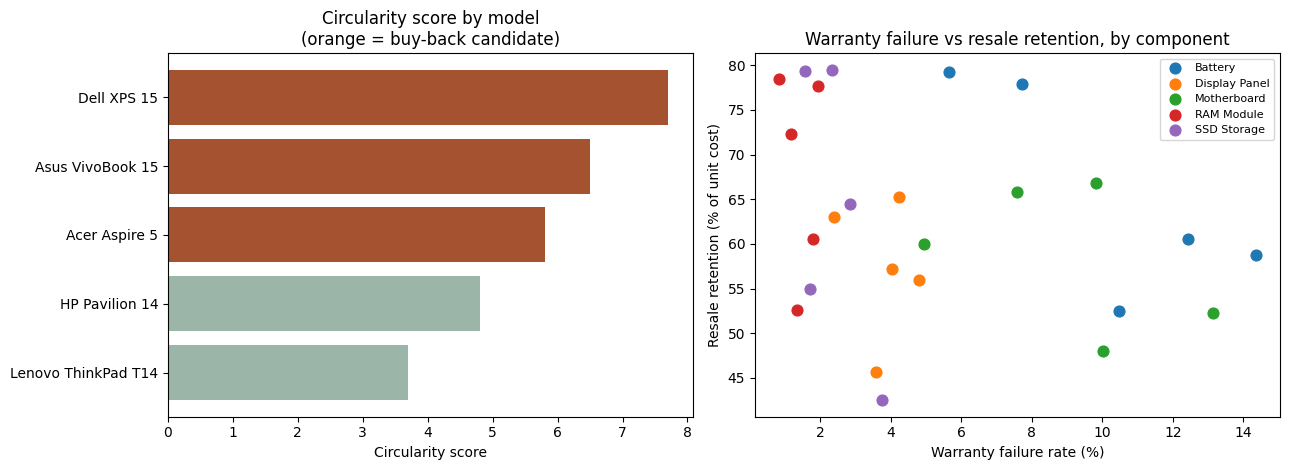

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: circularity score by model
colors = ["#a4522f" if r else "#9bb5a8" for r in model_scores["recommend_buyback_program"]]
axes[0].barh(model_scores["model"][::-1], model_scores["circularity_score"][::-1], color=colors[::-1])
axes[0].set_title("Circularity score by model\n(orange = buy-back candidate)")
axes[0].set_xlabel("Circularity score")

# Right: failure rate vs resale retention for every component
for comp, grp in component_scores.groupby("component"):
    axes[1].scatter(grp["warranty_failure_rate_pct"], grp["resale_retention_pct"], label=comp, s=60)
axes[1].set_title("Warranty failure vs resale retention, by component")
axes[1].set_xlabel("Warranty failure rate (%)")
axes[1].set_ylabel("Resale retention (% of unit cost)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

### Drill-down: component detail for the top-scoring model

In [8]:
top_model = model_scores.loc[0, "model"]
cols = ["component", "unit_cost_usd", "warranty_failure_rate_pct",
        "median_resale_price_usd", "resale_retention_pct", "listing_count"]
print(f"Top model: {top_model}")
component_scores[component_scores["model"] == top_model][cols].reset_index(drop=True)

Top model: Dell XPS 15


,component,unit_cost_usd,warranty_failure_rate_pct,median_resale_price_usd,resale_retention_pct,listing_count
0,Motherboard,180,13.13,94.200,52.3,16
1,Display Panel,90,4.80,50.350,55.9,17
2,Battery,35,14.36,20.535,58.7,12
3,RAM Module,25,1.93,19.420,77.7,9
4,SSD Storage,45,3.75,19.130,42.5,12


## 7. Save results

Results are written to a SQLite database (a stand-in for lakehouse tables) and an Excel
workbook that can be imported straight into Power BI.

In [9]:
conn = sqlite3.connect(DB_PATH)
bom.to_sql("bom", conn, if_exists="replace", index=False)
matched.to_sql("matched_listings", conn, if_exists="replace", index=False)
component_scores.to_sql("component_scores", conn, if_exists="replace", index=False)
model_scores.to_sql("model_scores", conn, if_exists="replace", index=False)
conn.close()

xlsx_path = os.path.join(OUTPUT_DIR, "EchoChain_Circularity_Report.xlsx")
with pd.ExcelWriter(xlsx_path, engine="openpyxl") as writer:
    model_scores.to_excel(writer, sheet_name="Model Scores", index=False)
    component_scores[["model", "component", "unit_cost_usd", "critical_component",
                      "warranty_failure_rate_pct", "median_resale_price_usd",
                      "resale_retention_pct", "listing_count"]].to_excel(
        writer, sheet_name="Component Detail", index=False)
    matched[["listing_id", "platform", "matched_model", "matched_component",
             "price_usd", "condition", "match_score"]].to_excel(
        writer, sheet_name="Matched Listings", index=False)

print("Saved:", DB_PATH, "and", xlsx_path)

Saved: echochain.db and outputs/EchoChain_Circularity_Report.xlsx


## 8. Findings

In [10]:
top = model_scores.iloc[0]
candidates = model_scores[model_scores["recommend_buyback_program"]]["model"].tolist()

print(f"Highest circularity score: {top['model']} ({top['circularity_score']})")
print(f"  Critical-component failure rate: {top['critical_failure_rate_pct']}%")
print(f"  Salvageable parts resale retention: {top['avg_salvageable_resale_retention_pct']}%")
print(f"\nBuy-back candidates: {', '.join(candidates) if candidates else 'none'}")

Highest circularity score: Dell XPS 15 (7.7)
  Critical-component failure rate: 13.1%
  Salvageable parts resale retention: 58.7%

Buy-back candidates: Dell XPS 15, Asus VivoBook 15, Acer Aspire 5


**Reading the result:** a model with a high critical failure rate has devices that get
scrapped, and if its remaining parts still resell for a large share of their original
cost, that value is being thrown away. That gap is the case for a buy-back and
refurbishment program.

### Limitations
- The listings and BOM are simulated, so the rankings demonstrate the method rather
  than real-world findings. Exact numbers change if the seed or generator changes.
- The score is a simple product of two rates. A production version would weight by
  sales volume, include refurbishment labour cost, and use actual component-level
  resale data rather than inferring it from titles.
- At scale, the cleaning, matching and aggregation steps map directly onto PySpark
  operations on Delta Lake tables.

### Next steps
- Replace the simulated listings with a Scrapy spider or an official marketplace API.
- Port the matching and aggregation to PySpark for larger volumes.
- Rebuild the executive dashboard natively in Power BI from the Excel export.